# KLAR：逐层局部量化误差与答案 margin 影响

沿用 notebook 29 的 **500 道英语锚定事实、12 个目标语言、5-shot chat prompt、FP16 与三种量化 checkpoint**。本 notebook 不重新生成答案；已有 baseline CSV 仅用于标记 FP16 是否答对。另加入 EN prompt 作为参照。

对每个 decoder block、同一批 prompt：

1. 将量化 block 的输入替换为 FP16 在该 block 的真实输入，取其输出与 FP16 block 输出之差 `e_l`。这隔离**该 block 的直接量化误差**，不包含前面层累计误差。
2. 只在 FP16 模型的第 `l` 个 block 输出注入 `e_l`，下游仍走 FP16，测下一 token 的正确答案 margin 变化和 KL。`ΔM_l<0` 表示此误差削弱正确 token 的相对优势；KL 只作辅助。

主 margin 使用**同一 prompt 最后位置**的 gold 首 token 与 FP16 最强非 gold token；这一候选对在 FP16、量化和各层干预之间保持不变。它是首 token 决策代理，**不等于完整答案正确率**。主汇总只用 FP16 已保存答案判对且 FP16 首 token 也偏向 gold 的目标语言样本。局部误差大小另在所有有效 prompt 上汇总。

首次运行默认先取保存清单的前 50 道事实并扫描所有层。核对输出后把 `FACT_LIMIT=500`，旧结果按方法／语言／层逐批复用。FP16 与量化模型**轮流**驻留同一张 GPU，中间隐状态暂存到磁盘；全 500 题仍会慢且需要足够磁盘空间。

In [1]:
import csv, gc, hashlib, json, os, random
from collections import Counter
from pathlib import Path

os.environ.setdefault('HF_ENDPOINT', 'https://hf-mirror.com')
os.environ.setdefault('HF_HOME', '/root/autodl-tmp/huggingface')
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

FP16_CHECKPOINT = Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-instruct')
QUANT_SPECS = {
    'GPTQ-INT4': {'kind': 'checkpoint',
                  'checkpoint': Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-gptq-int4')},
    'AWQ-INT4': {'kind': 'checkpoint',
                 'checkpoint': Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-awq-int4')},
    'BNB-NF4': {'kind': 'bnb_nf4', 'checkpoint': FP16_CHECKPOINT},
}
ACTIVE_QUANT_METHODS = ['GPTQ-INT4','AWQ-INT4','BNB-NF4']
ANALYSIS_ROOT = Path('/root/autodl-tmp/analysis')
KLAR_OUTPUT_DIR = ANALYSIS_ROOT / 'klar_gptq_english_500facts_template0_12languages_top1_fp16'
QUANT_BASELINE_DIRS = {
    'GPTQ-INT4': KLAR_OUTPUT_DIR,
    'AWQ-INT4': ANALYSIS_ROOT / 'klar_awq_all_aligned_facts_template0_12languages_top1_fp16',
    'BNB-NF4': ANALYSIS_ROOT / 'klar_bnb_english_500facts_template0_12languages_top1_fp16',
}
KLAR_DATA_DIR = Path('/root/autodl-tmp/data/klar')
OUTPUT_DIR = ANALYSIS_ROOT / 'klar_500_layerwise_local_error_margin_impact'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LANGUAGES = ['ca', 'en', 'es', 'fr', 'hu', 'nl', 'tr', 'ar', 'el', 'he', 'ja', 'ko', 'zh']
TARGET_LANGUAGES = [language for language in LANGUAGES if language != 'en']
KLAR_SAMPLE_TOTAL = 500
SEED = 2026
KLAR_SAMPLE_SEED = SEED + 50500
KLAR_N_SHOT = 5
KLAR_ADD_GENERATION_PROMPT = True
KLAR_MAX_LENGTH = 1024
TRUST_REMOTE_CODE = True
DTYPE = torch.float16
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

def load_tokenizer():
    tokenizer = AutoTokenizer.from_pretrained(FP16_CHECKPOINT,
                                              trust_remote_code=TRUST_REMOTE_CODE)
    tokenizer.padding_side = 'right'
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    return tokenizer

def load_model(name):
    if name == 'FP16':
        checkpoint, kwargs = FP16_CHECKPOINT, {'torch_dtype': DTYPE}
    else:
        spec = QUANT_SPECS[name]
        checkpoint = Path(spec['checkpoint'])
        kwargs = ({'quantization_config': BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type='nf4',
            bnb_4bit_compute_dtype=DTYPE)}
            if spec['kind'] == 'bnb_nf4' else {'torch_dtype': DTYPE})
    if not checkpoint.exists():
        raise FileNotFoundError(f'Missing model checkpoint: {checkpoint}')
    model = AutoModelForCausalLM.from_pretrained(
        checkpoint, device_map={'': 0}, low_cpu_mem_usage=True,
        trust_remote_code=TRUST_REMOTE_CODE, **kwargs).eval()
    model.config.use_cache = False
    placement = getattr(model, 'hf_device_map', None)
    if placement is not None and any(str(value) in ('cpu', 'disk', 'meta')
                                     for value in placement.values()):
        raise RuntimeError(f'{name} was offloaded outside GPU: {placement}')
    return model

def input_device(model):
    return model.get_input_embeddings().weight.device

TOKENIZER = load_tokenizer()
print('FP16 baseline:', KLAR_OUTPUT_DIR)
print('Output:', OUTPUT_DIR)


FP16 baseline: /root/autodl-tmp/analysis/klar_gptq_english_500facts_template0_12languages_top1_fp16
Output: /root/autodl-tmp/analysis/klar_500_layerwise_local_error_margin_impact


In [2]:
def load_klar_language(language):
    path = KLAR_DATA_DIR / f'{language}.json'
    if not path.is_file():
        raise FileNotFoundError(f'Missing KLAR file: {path}')
    raw = json.loads(path.read_text(encoding='utf-8'))
    flattened = []
    for relation_index, relation in enumerate(raw):
        relation_name = relation.get('relation_name', f'relation_{relation_index}')
        templates = relation['prompt_templates']
        for sample in relation['samples']:
            variants = []
            for template_id, template in enumerate(templates):
                variants.append({
                    'question': template.replace('<subject>', sample['subject']).split('<mask>')[0],
                    'answer': sample['object'],
                    'index': sample['index'],
                    'relation_name': relation_name,
                    'relation_id': relation.get('relation_id', ''),
                    'subject_en': sample['subject'] if language == 'en'
                                  else sample.get('subject_en', ''),
                    'object_en': sample['object'] if language == 'en'
                                 else sample.get('object_en', ''),
                    'template_id': template_id,
                })
            flattened.append(variants)
    if len(flattened) <= KLAR_N_SHOT:
        raise ValueError(f'{language}: fewer than {KLAR_N_SHOT + 1} facts')
    demonstrations = [flattened[i][i] for i in range(KLAR_N_SHOT)]
    return demonstrations, flattened[KLAR_N_SHOT:]

KLAR_RAW = {language: load_klar_language(language)
            for language in LANGUAGES}
def klar_prompt_messages(language, record_id, template_id):
    demonstrations, evaluation = KLAR_RAW[language]
    messages = []
    for demonstration in demonstrations:
        messages.extend([
            {'role': 'user', 'content': demonstration['question']},
            {'role': 'assistant', 'content': demonstration['answer']},
        ])
    current = evaluation[int(record_id)][int(template_id)]
    messages.append({'role': 'user', 'content': current['question']})
    return messages

def klar_prompt_text(language, record_id, template_id):
    return TOKENIZER.apply_chat_template(
        klar_prompt_messages(language, record_id, template_id),
        tokenize=False, add_generation_prompt=KLAR_ADD_GENERATION_PROMPT,
    )

def normalize_answer_for_match(text):
    import unicodedata
    value = unicodedata.normalize('NFKC', str(text))
    value = ' '.join(value.strip().split()).casefold()
    return value.strip(' \t\n\r.,;:!?。；：！？"\'`“”‘’()[]{}')

def answer_contains_gold(prediction, gold_answer):
    gold = normalize_answer_for_match(gold_answer)
    return bool(gold) and gold in normalize_answer_for_match(prediction)

_, english_evaluation = KLAR_RAW['en']
target_evaluations = {
    language: KLAR_RAW[language][1] for language in TARGET_LANGUAGES
}
for language, evaluation in target_evaluations.items():
    if len(evaluation) != len(english_evaluation):
        raise RuntimeError(
            f'{language}: {len(evaluation)} facts vs English '
            f'{len(english_evaluation)}; position-based pairing is unsafe.'
        )

def aligned_fact(record_id):
    english_variants = english_evaluation[record_id]
    if not english_variants:
        return False, 'English has no template'
    english = english_variants[0]
    for language, evaluation in target_evaluations.items():
        target_variants = evaluation[record_id]
        if not target_variants:
            return False, f'{language}: no template'
        target = target_variants[0]
        for field in ('index', 'relation_id'):
            if str(target[field]) != str(english[field]):
                return False, f'{language}: {field} mismatch'
        for field in ('subject_en', 'object_en'):
            if target[field] and str(target[field]).strip().casefold() != (
                str(english[field]).strip().casefold()
            ):
                return False, f'{language}: {field} mismatch'
    return True, ''

eligible_record_ids = []
excluded_reasons = Counter()
for record_id in range(len(english_evaluation)):
    valid, reason = aligned_fact(record_id)
    if valid:
        eligible_record_ids.append(record_id)
    else:
        excluded_reasons[reason] += 1
print('English facts eligible across all target languages:',
      len(eligible_record_ids), '/', len(english_evaluation))
if excluded_reasons:
    print('Excluded alignment reasons:', excluded_reasons.most_common(10))
if len(eligible_record_ids) < KLAR_SAMPLE_TOTAL:
    raise ValueError(
        f'Only {len(eligible_record_ids)} facts align across all target languages; '
        f'need {KLAR_SAMPLE_TOTAL}.'
    )
sample_manifest_path = KLAR_OUTPUT_DIR / 'sampled_english_500_question_ids.csv'
if not sample_manifest_path.is_file():
    raise FileNotFoundError(f'Saved 500-sample manifest required: {sample_manifest_path}')
sample_manifest = pd.read_csv(sample_manifest_path)
if len(sample_manifest) != KLAR_SAMPLE_TOTAL or sample_manifest['record_id'].duplicated().any():
    raise RuntimeError('Saved 500-sample manifest has wrong size or duplicate record IDs.')
if not sample_manifest['template_id'].eq(0).all():
    raise RuntimeError('This recovery expects template 0 for every saved fact.')
selected_record_ids = sample_manifest['record_id'].astype(int).tolist()
if not set(selected_record_ids).issubset(set(eligible_record_ids)):
    raise RuntimeError('Saved 500-sample manifest contains facts no longer aligned in KLAR.')
for record_id, fact_index in zip(selected_record_ids, sample_manifest['fact_index']):
    if str(english_evaluation[record_id][0]['index']) != str(fact_index):
        raise RuntimeError(f'Saved manifest fact_index mismatch at record {record_id}.')
SELECTED_RECORD_IDS_HASH = hashlib.sha256(
    json.dumps(selected_record_ids).encode()
).hexdigest()

KLAR_ROWS = {}
for language in TARGET_LANGUAGES:
    target_evaluation = target_evaluations[language]
    rows = []
    for record_id in selected_record_ids:
        target = target_evaluation[record_id][0]
        rows.append({
            'model': 'GPTQ-INT4', 'language': language,
            'sample_id': f'{language}:{record_id}:0',
            'english_sample_id': f'en:{record_id}:0',
            'record_id': record_id, 'template_id': 0,
            'relation_name': target['relation_name'],
            'gold_answer': target['answer'],
        })
    KLAR_ROWS[language] = rows
dataset_counts = pd.DataFrame([
    {'language': language, 'samples': len(KLAR_ROWS[language])}
    for language in TARGET_LANGUAGES
])
display(dataset_counts)
assert dataset_counts.samples.eq(KLAR_SAMPLE_TOTAL).all()
print('Sampled aligned English fact IDs:', len(selected_record_ids),
      '| target-language evaluations:', int(dataset_counts.samples.sum()),
      '| seed:', KLAR_SAMPLE_SEED)


English facts eligible across all target languages: 1338 / 1338


,language,samples
0,ca,500
1,es,500
2,fr,500
3,hu,500
4,nl,500
5,tr,500
6,ar,500
7,el,500
8,he,500
9,ja,500


Sampled aligned English fact IDs: 500 | target-language evaluations: 6000 | seed: 52526


In [3]:
def saved_bool(value):
    return str(value).strip().lower() in {'true', '1', '1.0', 'yes'}

def read_saved_predictions(path, expected_ids, output_col, correct_col, gold_by_id):
    if not path.is_file():
        raise FileNotFoundError(path)
    frame = pd.read_csv(path, dtype={'sample_id': str}).fillna('')
    needed = {'sample_id', 'gold_answer', output_col, correct_col}
    if not needed.issubset(frame.columns):
        raise RuntimeError(f'{path}: missing {needed - set(frame.columns)}')
    if frame['sample_id'].duplicated().any() or not expected_ids.issubset(set(frame['sample_id'])):
        raise RuntimeError(f'{path}: duplicate IDs or missing saved 500-sample IDs')
    selected = frame.loc[frame.sample_id.isin(expected_ids)].set_index('sample_id')
    records = selected.to_dict('index')
    for sample_id, record in records.items():
        if normalize_answer_for_match(record['gold_answer']) != normalize_answer_for_match(gold_by_id[sample_id]):
            raise RuntimeError(f'{path}: gold answer mismatch for {sample_id}')
        if bool(answer_contains_gold(record[output_col], gold_by_id[sample_id])) != saved_bool(record[correct_col]):
            raise RuntimeError(f'{path}: saved grade disagrees with notebook 26 for {sample_id}')
    return records

FP_SAVED, Q_SAVED = {}, {}
missing_baseline_rows = []
for language in TARGET_LANGUAGES:
    rows = KLAR_ROWS[language]
    ids = {row['sample_id'] for row in rows}
    gold = {row['sample_id']: row['gold_answer'] for row in rows}
    FP_SAVED[language] = read_saved_predictions(
        KLAR_OUTPUT_DIR / f'fp16_baseline_{language}.csv', ids,
        'fp16_output_text', 'fp16_correct', gold)

for method in ACTIVE_QUANT_METHODS:
    per_language = {}
    for language in TARGET_LANGUAGES:
        path = QUANT_BASELINE_DIRS[method] / f'baseline_{language}.csv'
        rows = KLAR_ROWS[language]
        ids = {row['sample_id'] for row in rows}
        gold = {row['sample_id']: row['gold_answer'] for row in rows}
        try:
            per_language[language] = read_saved_predictions(
                path, ids, 'baseline_output_text', 'baseline_correct', gold)
        except FileNotFoundError:
            missing_baseline_rows.append({'method': method, 'language': language,
                                          'missing_path': str(path)})
    if len(per_language) == len(TARGET_LANGUAGES):
        Q_SAVED[method] = per_language

if missing_baseline_rows:
    display(pd.DataFrame(missing_baseline_rows))
READY_METHODS = [method for method in ACTIVE_QUANT_METHODS if method in Q_SAVED]
if not READY_METHODS:
    raise RuntimeError('No quant method has complete saved baselines for 12 languages.')
print('Ready methods:', READY_METHODS)


Ready methods: ['GPTQ-INT4', 'AWQ-INT4', 'BNB-NF4']


## 1. 实验配置与固定探针

`FACT_LIMIT` 只限制这次运行的事实数，不改变缓存签名；从 50 扩展到 500 时不会重算已保存样本。`BATCH_SIZE` 可按显存调整。EN 没有在 notebook 29 中读取 baseline 正确性，因此 EN 仅作首 token 参照，不计入 Latin 组。

In [4]:
from contextlib import contextmanager
import inspect
import torch.nn.functional as F

FACT_LIMIT = 50  # 正式分析改为 500；必须 <= KLAR_SAMPLE_TOTAL
BATCH_SIZE = 2
LAYER_SELECTION = 'all'  # 或指定列表，如 [0, 1, 2, 3, 4, 5, 6, 7, 28, 29, 30, 31]
REQUIRE_FP_SAVED_CORRECT_FOR_IMPACT = True
REQUIRE_FP_TOP1_GOLD_FOR_IMPACT = True
ANALYSIS_LANGUAGES = ['en'] + TARGET_LANGUAGES
LATIN_LANGUAGES = {'ca', 'es', 'fr', 'hu', 'nl', 'tr'}
DIRECT_ERROR_DIR = OUTPUT_DIR / 'layerwise_local_error_margin'
DIRECT_ERROR_DIR.mkdir(parents=True, exist_ok=True)

if not 1 <= FACT_LIMIT <= KLAR_SAMPLE_TOTAL:
    raise ValueError('FACT_LIMIT must be between 1 and 500')
if not torch.cuda.is_available():
    raise RuntimeError('CUDA GPU is required; CPU offload would change this experiment')

# Preserve the same fact order across every language and quantization method.
KLAR_ROWS['en'] = [{
    'language': 'en', 'sample_id': f'en:{record_id}:0',
    'record_id': record_id, 'template_id': 0,
    'gold_answer': english_evaluation[record_id][0]['answer'],
    'relation_name': english_evaluation[record_id][0]['relation_name'],
} for record_id in selected_record_ids]

def gold_first_token(prompt, gold):
    prefix = TOKENIZER(prompt, add_special_tokens=False)['input_ids']
    together = TOKENIZER(prompt + str(gold), add_special_tokens=False)['input_ids']
    if not prefix or len(together) <= len(prefix) or together[:len(prefix)] != prefix:
        return None, 'gold does not tokenize as a continuation of this prompt'
    if len(prefix) > KLAR_MAX_LENGTH:
        return None, 'prompt exceeds KLAR_MAX_LENGTH'
    return (prefix, int(together[len(prefix)])), ''

PROBES, PROBE_EXCLUSIONS = {}, []
for language in ANALYSIS_LANGUAGES:
    valid = []
    for row in KLAR_ROWS[language][:FACT_LIMIT]:
        prompt = klar_prompt_text(language, row['record_id'], row['template_id'])
        pair, reason = gold_first_token(prompt, row['gold_answer'])
        if reason:
            PROBE_EXCLUSIONS.append({**row, 'reason': reason})
            continue
        fp_status = (saved_bool(FP_SAVED[language][row['sample_id']]['fp16_correct'])
                     if language != 'en' else None)
        valid.append({**row, 'input_ids': pair[0], 'gold_token_id': pair[1],
                      'fp_saved_correct': fp_status,
                      'script_group': ('English' if language == 'en' else
                                       'Latin' if language in LATIN_LANGUAGES else 'Non-Latin')})
    PROBES[language] = valid
    print(f'{language}: {len(valid)}/{FACT_LIMIT} prompt/gold probes usable')
pd.DataFrame(PROBE_EXCLUSIONS).to_csv(DIRECT_ERROR_DIR / 'probe_exclusions.csv', index=False)
if not all(PROBES.values()):
    raise RuntimeError('At least one language has no valid prompt/gold probes')


RuntimeError: CUDA GPU is required; CPU offload would change this experiment

## 2. GPU 前向、逐层 hook 与断点缓存

量化 block 的 `forward_pre_hook` 在每层入口放入对应 FP16 隐状态；`forward_hook` 收集该层输出。因此**一次量化模型前向**即可取得本批所有层的局部误差。然后逐层将误差注入 FP16 block 输出，继续完整 FP16 下游。两个模型均使用相同 `input_ids`、attention mask 与 position IDs。每一小批完成一个层后立刻原子写入该方法／语言／层的 CSV；中断后只补缺失题目。

误差大小同时报告有效 prompt token 的相对 RMS 误差和**最后一个 token**的相对范数。纵轴的任务影响是 `M_patched−M_FP`，不是误差范数。

In [6]:
def decoder_layers(model):
    backbone = getattr(model, 'model', None)
    layers = getattr(backbone, 'layers', None)
    if layers is None:
        raise RuntimeError(f'{type(model).__name__}: expected model.layers')
    return layers

def first_hidden(output):
    return output[0] if isinstance(output, (tuple, list)) else output

def replace_hidden(output, hidden):
    if isinstance(output, tuple):
        return (hidden,) + output[1:]
    if isinstance(output, list):
        return [hidden] + output[1:]
    return hidden

def make_batch(probes, device):
    max_len = max(len(p['input_ids']) for p in probes)
    ids = torch.full((len(probes), max_len), TOKENIZER.pad_token_id,
                     dtype=torch.long, device=device)
    mask = torch.zeros_like(ids)
    for i, probe in enumerate(probes):
        row = torch.tensor(probe['input_ids'], dtype=torch.long, device=device)
        ids[i, -len(row):] = row  # left padding: final prompt token is always at -1
        mask[i, -len(row):] = 1
    position_ids = (mask.cumsum(-1) - 1).clamp(min=0)
    return {'input_ids': ids, 'attention_mask': mask, 'position_ids': position_ids}

def model_forward(model, batch):
    kwargs = dict(batch, use_cache=False, return_dict=True)
    parameters = inspect.signature(model.forward).parameters
    if 'logits_to_keep' in parameters:
        kwargs['logits_to_keep'] = 1
    elif 'num_logits_to_keep' in parameters:
        kwargs['num_logits_to_keep'] = 1
    return model(**kwargs)

def final_logits(outputs):
    return outputs.logits[:, -1, :].float()

@torch.inference_mode()
def fp_baseline_and_states(model, batch):
    layers = decoder_layers(model)
    states = {}
    handles = []
    def capture(layer_index):
        def hook(module, args, output):
            if layer_index == 0:
                states['input0'] = args[0].detach().cpu().clone()
            states[layer_index] = first_hidden(output).detach().cpu().clone()
        return hook
    try:
        for layer_index, layer in enumerate(layers):
            handles.append(layer.register_forward_hook(capture(layer_index)))
        logits = final_logits(model_forward(model, batch)).detach()
    finally:
        for handle in handles:
            handle.remove()
    if len([key for key in states if isinstance(key, int)]) != len(layers):
        raise RuntimeError('FP16 hidden-state capture incomplete')
    return logits, states

@torch.inference_mode()
def quant_all_local_outputs_on_fp_inputs(model, batch, fp_states, selected_layers):
    layers = decoder_layers(model)
    captured, handles = {}, []
    def set_input(layer_index):
        def hook(module, args):
            hidden = args[0]
            fp_input = fp_states['input0' if layer_index == 0 else layer_index-1]
            replacement = fp_input.to(device=hidden.device, dtype=hidden.dtype)
            if replacement.shape != hidden.shape:
                raise RuntimeError(f'Layer {layer_index}: FP/quant hidden shape mismatch')
            return (replacement,) + args[1:]
        return hook
    def take_output(layer_index):
        def hook(module, args, output):
            if layer_index in selected_layers:
                captured[layer_index] = first_hidden(output).detach().cpu().clone()
        return hook
    try:
        for layer_index, layer in enumerate(layers):
            handles.append(layer.register_forward_pre_hook(set_input(layer_index)))
            handles.append(layer.register_forward_hook(take_output(layer_index)))
        model_forward(model, batch)
    finally:
        for handle in handles:
            handle.remove()
    if set(captured) != set(selected_layers):
        raise RuntimeError(f'Quant local outputs incomplete: {set(selected_layers)-set(captured)}')
    return captured

@torch.inference_mode()
def fp_with_one_layer_error(model, batch, layer_index, error):
    layer = decoder_layers(model)[layer_index]
    def inject(module, args, output):
        hidden = first_hidden(output)
        if hidden.shape != error.shape:
            raise RuntimeError(f'Layer {layer_index}: patch shape mismatch')
        return replace_hidden(output, hidden + error.to(hidden.device, hidden.dtype))
    handle = layer.register_forward_hook(inject)
    try:
        return final_logits(model_forward(model, batch)).detach()
    finally:
        handle.remove()

def cache_path(method, language, layer_index):
    stem = method.lower().replace('-', '_')
    return DIRECT_ERROR_DIR / f'{stem}_{language}_layer{layer_index:02d}.csv'

def read_layer_cache(method, language, layer_index, fingerprint):
    path = cache_path(method, language, layer_index)
    if not path.is_file():
        return pd.DataFrame(), set()
    frame = pd.read_csv(path, dtype={'sample_id': str})
    if not {'sample_id', 'fingerprint'}.issubset(frame.columns):
        raise RuntimeError(f'Invalid cache columns: {path}')
    if not frame.fingerprint.eq(fingerprint).all():
        raise RuntimeError(f'Cache protocol/model mismatch; preserve and inspect: {path}')
    if frame.sample_id.duplicated().any():
        raise RuntimeError(f'Duplicate sample_id: {path}')
    return frame, set(frame.sample_id)

def save_layer_cache(method, language, layer_index, old_frame, new_rows):
    if not new_rows:
        return old_frame
    path = cache_path(method, language, layer_index)
    merged = pd.concat([old_frame, pd.DataFrame(new_rows)], ignore_index=True)
    merged = merged.drop_duplicates('sample_id', keep='last')
    temporary = path.with_suffix('.tmp')
    merged.to_csv(temporary, index=False, encoding='utf-8-sig')
    temporary.replace(path)
    return merged

def fingerprint_for(method):
    return hashlib.sha256(json.dumps({
        'protocol': 'same_fp_input_block_error_then_fp_downstream_margin_v3',
        'fp_checkpoint': str(FP16_CHECKPOINT),
        'quant_method': method,
        'quant_checkpoint': str(QUANT_SPECS[method]['checkpoint']),
        'selected_record_ids_hash': SELECTED_RECORD_IDS_HASH,
        'n_shot': KLAR_N_SHOT, 'chat_prompt': KLAR_ADD_GENERATION_PROMPT,
        'candidate_rule': 'fp_top_non_gold_at_first_gold_token',
    }, sort_keys=True).encode()).hexdigest()
print('Cache fingerprints:', {m: fingerprint_for(m)[:12] for m in READY_METHODS})


Cache fingerprints: {'GPTQ-INT4': 'a50b6964f307', 'AWQ-INT4': 'fecacc3c0f30', 'BNB-NF4': '2b1f1cd12fa5'}


## 3. 分阶段运行：单张 GPU 不同时加载两个模型

按语言处理：先由 FP16 缓存该语言当前批次的逐层隐状态；卸载 FP16 后加载一个量化模型，计算同输入局部误差；卸载量化模型后重新加载 FP16，逐层注入误差并保存结果。各阶段的中间文件与最终 CSV 均可断点续跑。一个阶段结束后会卸载模型并清理显存。默认完成一批后删除其临时中间文件，以控制磁盘占用。

**请先重启内核再从第 1 格顺序运行**，避免上次 OOM 的模型对象仍被 notebook traceback 引用。调小 `BATCH_SIZE` 可降低前向的激活占用，但不影响模型权重占用。正式 500 题、全 32 层和三种方法仍会耗时较长。

In [7]:
from transformers import AutoConfig

RUN_METHODS = READY_METHODS
KEEP_STAGE_CACHE = False  # 完成最终 CSV 后清理临时隐状态/误差文件；最终结果不会删除
STAGE_DIR = DIRECT_ERROR_DIR / 'staging'
STAGE_DIR.mkdir(parents=True, exist_ok=True)
if not RUN_METHODS:
    raise RuntimeError('No complete saved quant baseline available')

model_config = AutoConfig.from_pretrained(FP16_CHECKPOINT,
                                          trust_remote_code=TRUST_REMOTE_CODE)
num_layers = int(model_config.num_hidden_layers)
layer_ids = (list(range(num_layers)) if LAYER_SELECTION == 'all'
             else sorted(set(int(x) for x in LAYER_SELECTION)))
if not layer_ids or any(layer < 0 or layer >= num_layers for layer in layer_ids):
    raise ValueError('LAYER_SELECTION contains an invalid layer or is empty')

fp_stage_fingerprint = hashlib.sha256(json.dumps({
    'protocol': 'fp_states_for_single_gpu_staging_v1',
    'fp_checkpoint': str(FP16_CHECKPOINT),
    'manifest': SELECTED_RECORD_IDS_HASH,
    'n_shot': KLAR_N_SHOT,
    'chat_prompt': KLAR_ADD_GENERATION_PROMPT,
}, sort_keys=True).encode()).hexdigest()

def stage_batch_key(batch_probes):
    joined = '|'.join(probe['sample_id'] for probe in batch_probes)
    return hashlib.sha256(joined.encode()).hexdigest()[:20]

def fp_stage_path(language, batch_probes):
    return STAGE_DIR / f'fp_{language}_{stage_batch_key(batch_probes)}.pt'

def quant_stage_path(method, language, batch_probes):
    stem = method.lower().replace('-', '_')
    selection = hashlib.sha256(str(layer_ids).encode()).hexdigest()[:8]
    return STAGE_DIR / f'q_{stem}_{language}_{selection}_{stage_batch_key(batch_probes)}.pt'

def load_stage(path, fingerprint, batch_probes):
    if not path.is_file():
        return None
    payload = torch.load(path, map_location='cpu', weights_only=False)
    expected_ids = [probe['sample_id'] for probe in batch_probes]
    if payload.get('fingerprint') != fingerprint or payload.get('sample_ids') != expected_ids:
        raise RuntimeError(f'Incompatible stage cache; inspect rather than overwrite: {path}')
    return payload

def save_stage(path, payload):
    temporary = path.with_suffix('.pt.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)

def clear_gpu_after_unload():
    gc.collect()
    torch.cuda.empty_cache()
    print('CUDA allocated after unload:',
          round(torch.cuda.memory_allocated(0) / 1024**3, 2), 'GiB')

def missing_layers_for_batch(cache, batch_probes):
    return [layer for layer in layer_ids
            if any(probe['sample_id'] not in cache[layer][1] for probe in batch_probes)]

for language in ANALYSIS_LANGUAGES:
    batches = [PROBES[language][start:start+BATCH_SIZE]
               for start in range(0, len(PROBES[language]), BATCH_SIZE)]
    method_cache = {}
    method_batches = {}
    for method in RUN_METHODS:
        fingerprint = fingerprint_for(method)
        cache = {}
        for layer in layer_ids:
            frame, done = read_layer_cache(method, language, layer, fingerprint)
            cache[layer] = [frame, done]
        method_cache[method] = cache
        method_batches[method] = [
            batch for batch in batches if missing_layers_for_batch(cache, batch)
        ]
    active_batches = [
        batch for batch in batches
        if any(missing_layers_for_batch(method_cache[method], batch)
               for method in RUN_METHODS)
    ]
    if not active_batches:
        print(language, ': all requested sample/layer/method rows already saved')
        continue

    # Stage 1: FP16 alone on GPU. Hidden states are cached on CPU/disk for this language.
    fp_missing = [batch for batch in active_batches
                  if not fp_stage_path(language, batch).is_file()]
    if fp_missing:
        fp_model = None
        try:
            fp_model = load_model('FP16')
            if len(decoder_layers(fp_model)) != num_layers:
                raise RuntimeError('FP16 checkpoint layer count differs from config')
            for batch_probes in tqdm(fp_missing, desc=f'FP16 states:{language}'):
                batch_fp = make_batch(batch_probes, input_device(fp_model))
                fp_logits, fp_states = fp_baseline_and_states(fp_model, batch_fp)
                save_stage(fp_stage_path(language, batch_probes), {
                    'fingerprint': fp_stage_fingerprint,
                    'sample_ids': [probe['sample_id'] for probe in batch_probes],
                    'logits': fp_logits.cpu(),
                    'states': fp_states,
                })
                del batch_fp, fp_logits, fp_states
        finally:
            if fp_model is not None:
                del fp_model
            clear_gpu_after_unload()

    for method in RUN_METHODS:
        active_for_method = method_batches[method]
        if not active_for_method:
            continue
        fingerprint = fingerprint_for(method)
        cache = method_cache[method]

        # Stage 2: quantized model alone on GPU. Native Q logits and direct block errors.
        q_missing = [
            batch for batch in active_for_method
            if not quant_stage_path(method, language, batch).is_file()
        ]
        if q_missing:
            q_model = None
            try:
                q_model = load_model(method)
                if len(decoder_layers(q_model)) != num_layers:
                    raise RuntimeError(f'{method}: layer count differs from FP16')
                for batch_probes in tqdm(q_missing, desc=f'Quant local errors:{method}:{language}'):
                    fp_data = load_stage(fp_stage_path(language, batch_probes),
                                         fp_stage_fingerprint, batch_probes)
                    needed_layers = missing_layers_for_batch(cache, batch_probes)
                    batch_q = make_batch(batch_probes, input_device(q_model))
                    with torch.inference_mode():
                        q_logits = final_logits(model_forward(q_model, batch_q)).detach().cpu()
                        local_outputs = quant_all_local_outputs_on_fp_inputs(
                            q_model, batch_q, fp_data['states'], needed_layers)
                    mask = batch_q['attention_mask'].bool().cpu()
                    errors, direct_metrics = {}, {}
                    for layer in needed_layers:
                        fp_output = fp_data['states'][layer].float()
                        error = local_outputs[layer].float() - fp_output
                        error_sq = error.square().sum(-1)
                        fp_sq = fp_output.square().sum(-1)
                        all_ratio = torch.sqrt(
                            (error_sq * mask).sum(-1) /
                            (fp_sq * mask).sum(-1).clamp_min(1e-12))
                        last_norm = error[:, -1].norm(dim=-1)
                        last_ratio = last_norm / fp_output[:, -1].norm(dim=-1).clamp_min(1e-12)
                        errors[layer] = error.half()
                        direct_metrics[layer] = {
                            'all_ratio': all_ratio, 'last_ratio': last_ratio,
                            'last_norm': last_norm}
                        del fp_output, error
                    save_stage(quant_stage_path(method, language, batch_probes), {
                        'fingerprint': fingerprint,
                        'sample_ids': [probe['sample_id'] for probe in batch_probes],
                        'q_logits': q_logits,
                        'errors': errors,
                        'direct_metrics': direct_metrics,
                    })
                    del fp_data, batch_q, q_logits, local_outputs, mask, errors, direct_metrics
            finally:
                if q_model is not None:
                    del q_model
                clear_gpu_after_unload()

        # Stage 3: FP16 alone on GPU. Inject each layer's saved local error.
        fp_model = None
        try:
            fp_model = load_model('FP16')
            for batch_probes in tqdm(active_for_method, desc=f'FP16 downstream:{method}:{language}'):
                needed_layers = missing_layers_for_batch(cache, batch_probes)
                if not needed_layers:
                    continue
                fp_data = load_stage(fp_stage_path(language, batch_probes),
                                     fp_stage_fingerprint, batch_probes)
                q_data = load_stage(quant_stage_path(method, language, batch_probes),
                                    fingerprint, batch_probes)
                if q_data is None or not set(needed_layers).issubset(q_data['errors']):
                    raise RuntimeError(f'Quant error stage is incomplete for {method}/{language}')
                batch_fp = make_batch(batch_probes, input_device(fp_model))
                fp_logits = fp_data['logits'].to(batch_fp['input_ids'].device)
                q_logits = q_data['q_logits'].to(fp_logits.device)
                gold_ids = torch.tensor([p['gold_token_id'] for p in batch_probes],
                                        device=fp_logits.device, dtype=torch.long)
                top2 = fp_logits.topk(2, dim=-1).indices
                foil_ids = torch.where(top2[:, 0].eq(gold_ids), top2[:, 1], top2[:, 0])
                batch_idx = torch.arange(len(batch_probes), device=fp_logits.device)
                fp_margin = fp_logits[batch_idx, gold_ids] - fp_logits[batch_idx, foil_ids]
                q_margin = q_logits[batch_idx, gold_ids] - q_logits[batch_idx, foil_ids]
                fp_probs = F.softmax(fp_logits, dim=-1)
                fp_log_probs = F.log_softmax(fp_logits, dim=-1)
                fp_top_gold = top2[:, 0].eq(gold_ids)

                for layer in needed_layers:
                    missing = [p['sample_id'] not in cache[layer][1] for p in batch_probes]
                    error = q_data['errors'][layer].to(fp_logits.device)
                    patched_logits = fp_with_one_layer_error(fp_model, batch_fp, layer, error)
                    patched_margin = patched_logits[batch_idx, gold_ids] - \
                                     patched_logits[batch_idx, foil_ids]
                    patched_kl = (fp_probs * (
                        fp_log_probs - F.log_softmax(patched_logits, dim=-1)
                    )).sum(-1).clamp_min(0)
                    metrics = q_data['direct_metrics'][layer]
                    rows = []
                    for i, probe in enumerate(batch_probes):
                        if not missing[i]:
                            continue
                        rows.append({
                            'fingerprint': fingerprint, 'method': method,
                            'language': language, 'script_group': probe['script_group'],
                            'sample_id': probe['sample_id'], 'record_id': probe['record_id'],
                            'layer': layer, 'fp_saved_correct': probe['fp_saved_correct'],
                            'quant_saved_correct': (None if language == 'en' else
                                saved_bool(Q_SAVED[method][language][probe['sample_id']]['baseline_correct'])),
                            'fp_top1_gold': bool(fp_top_gold[i].item()),
                            'prompt_tokens': int(batch_fp['attention_mask'][i].sum().item()),
                            'gold_token_id': int(gold_ids[i].item()),
                            'foil_token_id': int(foil_ids[i].item()),
                            'fp_margin': float(fp_margin[i].item()),
                            'quant_margin_same_pair': float(q_margin[i].item()),
                            'direct_error_all_token_ratio': float(metrics['all_ratio'][i].item()),
                            'direct_error_last_token_ratio': float(metrics['last_ratio'][i].item()),
                            'direct_error_last_token_norm': float(metrics['last_norm'][i].item()),
                            'patched_margin': float(patched_margin[i].item()),
                            'delta_margin': float((patched_margin[i]-fp_margin[i]).item()),
                            'patched_next_token_kl': float(patched_kl[i].item()),
                        })
                    cache[layer][0] = save_layer_cache(
                        method, language, layer, cache[layer][0], rows)
                    cache[layer][1].update(row['sample_id'] for row in rows)
                    del error, patched_logits

                del fp_data, q_data, batch_fp, fp_logits, q_logits, gold_ids
                del top2, foil_ids, batch_idx, fp_margin, q_margin, fp_probs, fp_log_probs
                if not missing_layers_for_batch(cache, batch_probes) and not KEEP_STAGE_CACHE:
                    quant_stage_path(method, language, batch_probes).unlink(missing_ok=True)
        finally:
            if fp_model is not None:
                del fp_model
            clear_gpu_after_unload()

    if not KEEP_STAGE_CACHE:
        for batch_probes in active_batches:
            if all(not missing_layers_for_batch(method_cache[method], batch_probes)
                   for method in RUN_METHODS):
                fp_stage_path(language, batch_probes).unlink(missing_ok=True)
    print(language, ': completed current requested methods/layers')

print('Layerwise experiment complete for current FACT_LIMIT / LAYER_SELECTION.')


NameError: name 'PROBES' is not defined

## 4. 汇总、组间比较与图

第一张图在**所有有效 prompt**上计算直接误差。第二张图只保留保存答案 FP16 正确、且首 token gold 排名第一的目标语言样本；EN 使用首 token gold 排名第一的题目作参照。脚本组曲线先对每种语言求均值，再对组内语言等权平均，避免样本数量不同的语言独占一组。误差带表示六种语言均值的标准误，不是 500 个事实的配对置信区间。逐样本 CSV 可进一步按事实 ID 做配对 bootstrap。

,method,language,probes,impact_probes
0,AWQ-INT4,ar,50,29
1,AWQ-INT4,ca,50,37
2,AWQ-INT4,el,50,25
3,AWQ-INT4,en,50,44
4,AWQ-INT4,es,50,42
5,AWQ-INT4,fr,50,42
6,AWQ-INT4,he,50,34
7,AWQ-INT4,hu,50,37
8,AWQ-INT4,ja,50,38
9,AWQ-INT4,ko,50,32


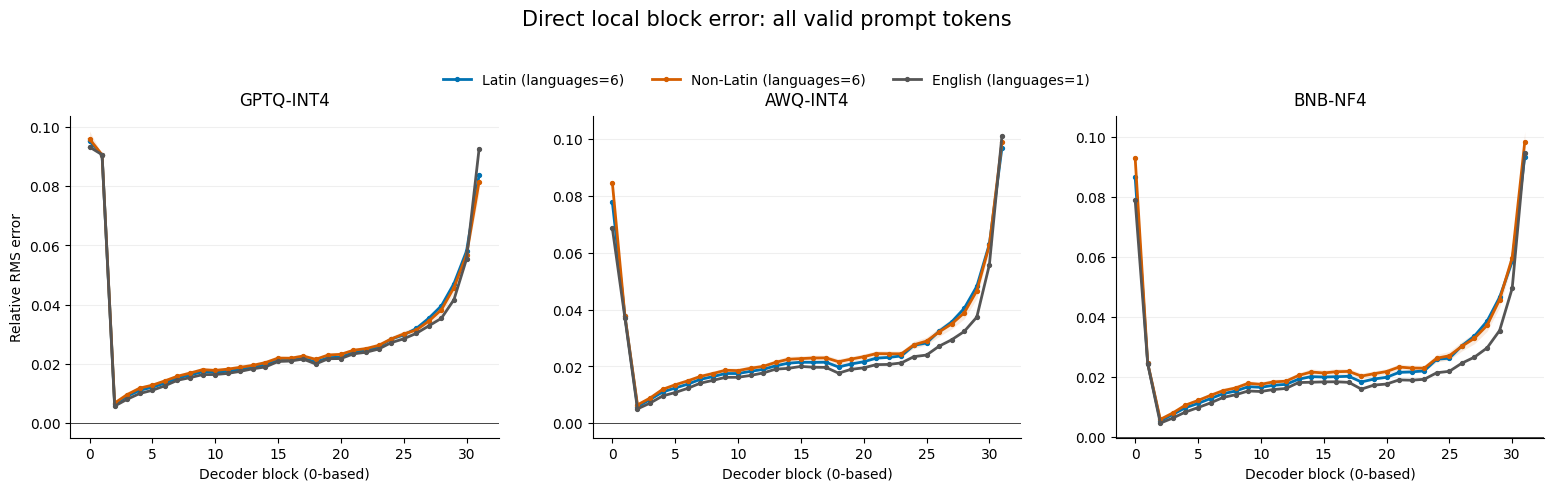

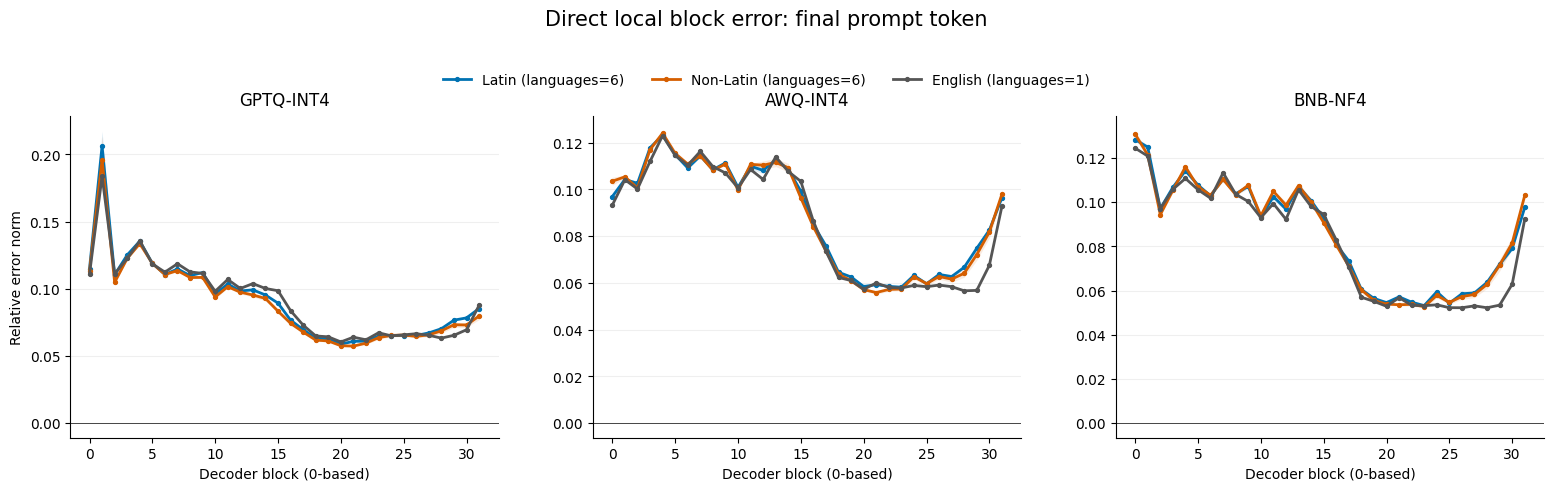

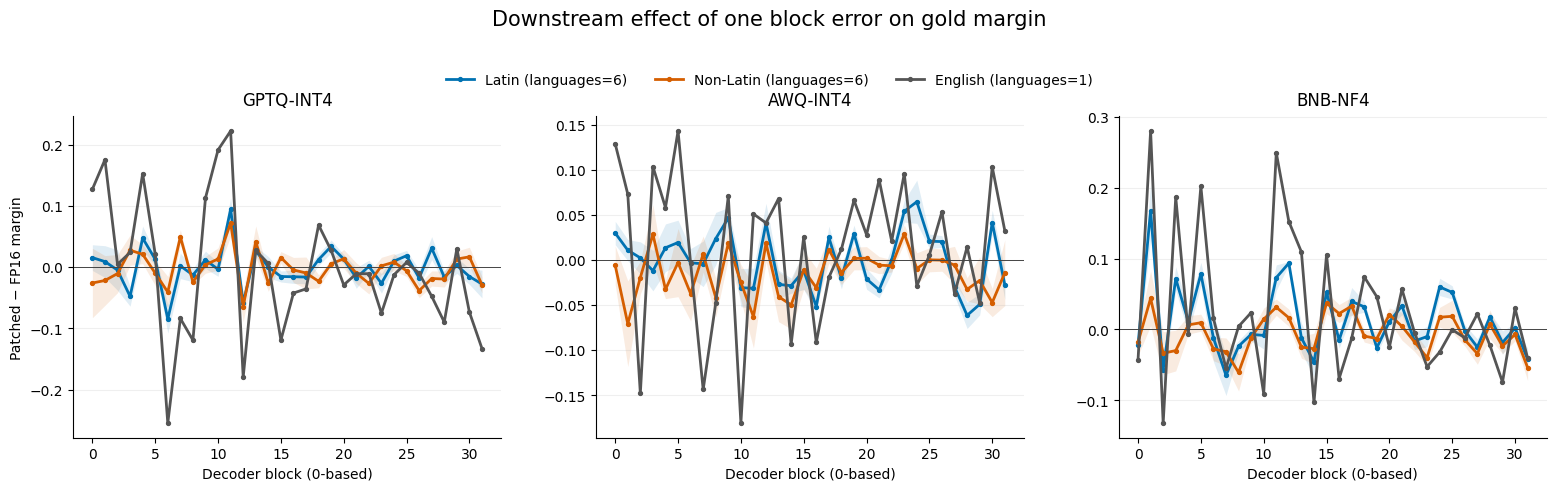

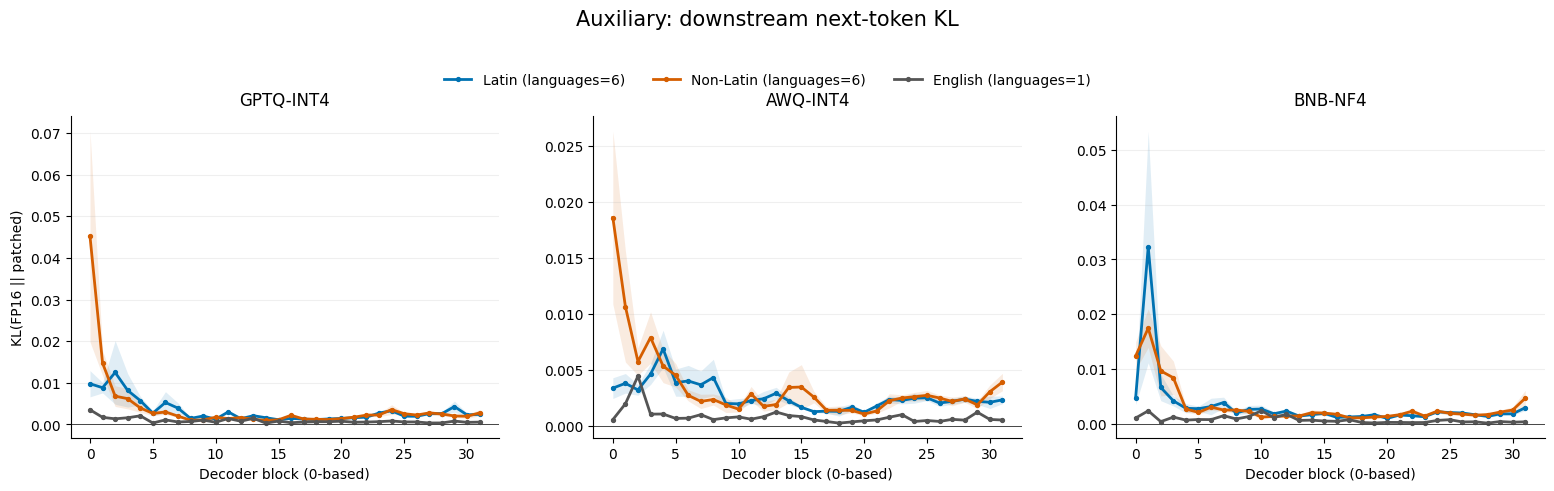

Negative delta_margin is harmful to the fixed gold-vs-foil decision.
Positive KL means changed distribution, not necessarily worse answer.


method     script_group  saved_outcome               
AWQ-INT4   Latin         FP16 correct / quant correct    223
                         FP16 correct / quant wrong       17
           Non-Latin     FP16 correct / quant correct    174
                         FP16 correct / quant wrong       19
BNB-NF4    Latin         FP16 correct / quant correct    227
                         FP16 correct / quant wrong       13
           Non-Latin     FP16 correct / quant correct    179
                         FP16 correct / quant wrong       14
GPTQ-INT4  Latin         FP16 correct / quant correct    224
                         FP16 correct / quant wrong       16
           Non-Latin     FP16 correct / quant correct    179
                         FP16 correct / quant wrong       14
Name: n_probes, dtype: int64

In [8]:
all_frames = []
for method in RUN_METHODS:
    for language in ANALYSIS_LANGUAGES:
        for path in sorted(DIRECT_ERROR_DIR.glob(
            f'{method.lower().replace("-", "_")}_{language}_layer*.csv'
        )):
            frame = pd.read_csv(path, dtype={'sample_id': str})
            if not frame.fingerprint.eq(fingerprint_for(method)).all():
                raise RuntimeError(f'Incompatible cache: {path}')
            all_frames.append(frame)
if not all_frames:
    raise RuntimeError('No cached layer results to summarize')
results_df = pd.concat(all_frames, ignore_index=True)
results_df.to_csv(DIRECT_ERROR_DIR / 'all_sample_layer_results.csv',
                  index=False, encoding='utf-8-sig')

correct_flag = results_df.fp_saved_correct.astype(str).str.lower().isin(['true', '1', '1.0'])
top1_flag = results_df.fp_top1_gold.astype(str).str.lower().isin(['true', '1', '1.0'])
impact_mask = (top1_flag if REQUIRE_FP_TOP1_GOLD_FOR_IMPACT else pd.Series(True, index=results_df.index))
if REQUIRE_FP_SAVED_CORRECT_FOR_IMPACT:
    impact_mask &= (correct_flag | results_df.language.eq('en'))
impact_df = results_df[impact_mask].copy()
coverage = (results_df.groupby(['method', 'language'])['sample_id'].nunique()
            .rename('probes').reset_index())
impact_coverage = (impact_df.groupby(['method', 'language'])['sample_id'].nunique()
                   .rename('impact_probes').reset_index())
coverage = coverage.merge(impact_coverage, on=['method', 'language'], how='left').fillna(0)
coverage.to_csv(DIRECT_ERROR_DIR / 'impact_probe_coverage.csv', index=False)
display(coverage)

def language_equal_summary(frame, metric):
    by_language = (frame.groupby(['method', 'layer', 'script_group', 'language'], as_index=False)
                   .agg(value=(metric, 'mean'), n_samples=('sample_id', 'nunique')))
    by_group = (by_language.groupby(['method', 'layer', 'script_group'], as_index=False)
                .agg(mean=('value', 'mean'), std=('value', 'std'),
                     n_languages=('language', 'nunique'),
                     n_samples=('n_samples', 'sum')))
    by_group['se'] = by_group['std'].fillna(0) / np.sqrt(by_group['n_languages'])
    return by_group

metric_specs = [
    ('direct_error_all_token_ratio', results_df,
     'Direct local block error: all valid prompt tokens', 'Relative RMS error'),
    ('direct_error_last_token_ratio', results_df,
     'Direct local block error: final prompt token', 'Relative error norm'),
    ('delta_margin', impact_df,
     'Downstream effect of one block error on gold margin', 'Patched − FP16 margin'),
    ('patched_next_token_kl', impact_df,
     'Auxiliary: downstream next-token KL', 'KL(FP16 || patched)'),
]
summaries = {}
for metric, frame, title, ylabel in metric_specs:
    summary = language_equal_summary(frame, metric)
    summary.to_csv(DIRECT_ERROR_DIR / f'group_{metric}.csv', index=False)
    summaries[metric] = summary
    fig, axes = plt.subplots(1, len(RUN_METHODS), figsize=(5.4*len(RUN_METHODS), 5.1),
                             sharex=True, sharey=False)
    if len(RUN_METHODS) == 1:
        axes = [axes]
    fig.subplots_adjust(left=0.07, right=0.98, bottom=0.15, top=0.78, wspace=0.22)
    for ax, method in zip(axes, RUN_METHODS):
        panel = summary[summary.method.eq(method)]
        for group, color in [('Latin', '#0072B2'), ('Non-Latin', '#D55E00'),
                             ('English', '#555555')]:
            curve = panel[panel.script_group.eq(group)].sort_values('layer')
            if curve.empty:
                continue
            x, y, se = (curve.layer.to_numpy(float), curve['mean'].to_numpy(float),
                        curve.se.to_numpy(float))
            ax.plot(x, y, color=color, linewidth=2, marker='o', markersize=2.8,
                    label=f'{group} (languages={int(curve.n_languages.iloc[0])})')
            ax.fill_between(x, y-se, y+se, color=color, alpha=0.12, linewidth=0)
        ax.set_title(method, fontsize=12, pad=8)
        ax.set_xlabel('Decoder block (0-based)')
        ax.axhline(0, color='#444444', linewidth=0.7)
        ax.grid(axis='y', alpha=0.2)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylabel(ylabel)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=3,
               bbox_to_anchor=(0.5, 0.89), frameon=False)
    fig.suptitle(title, y=0.99, fontsize=15)
    stem = DIRECT_ERROR_DIR / f'figure_{metric}'
    fig.savefig(stem.with_suffix('.png'), dpi=220, bbox_inches='tight')
    fig.savefig(stem.with_suffix('.pdf'), bbox_inches='tight')
    plt.show()

print('Negative delta_margin is harmful to the fixed gold-vs-foil decision.')
print('Positive KL means changed distribution, not necessarily worse answer.')

# Fixed-baseline outcome comparison; descriptive, not an unconfounded causal estimate.
outcomes = impact_df[impact_df.language.ne('en')].copy()
q_correct = outcomes.quant_saved_correct.astype(str).str.lower().isin(['true', '1', '1.0'])
outcomes['saved_outcome'] = np.where(q_correct, 'FP16 correct / quant correct',
                                     'FP16 correct / quant wrong')
outcome_summary = (outcomes.groupby(['method', 'script_group', 'saved_outcome', 'layer'], as_index=False)
                   .agg(mean_delta_margin=('delta_margin', 'mean'),
                        mean_kl=('patched_next_token_kl', 'mean'),
                        n_probes=('sample_id', 'nunique')))
outcome_summary.to_csv(DIRECT_ERROR_DIR / 'outcome_stratified_layer_impact.csv',
                       index=False, encoding='utf-8-sig')
display(outcome_summary.groupby(['method', 'script_group', 'saved_outcome'])['n_probes'].max())


## 5. 解读界限

- 这里是 **decoder block** 的局部误差，不单独区分 attention 与 MLP。若早层显著，下一步才分离两条子路径。
- 注入的是自然量化误差 `Q_l(h_l^FP)−FP_l(h_l^FP)`；除这一层外，下游均为 FP16，因此它不同于完整量化模型的累计误差，也不应把每层效应简单相加。
- `ΔM_l` 是固定 gold／foil 首 token 的方向性任务指标；它比 KL 更贴近决策，但仍不能直接等同完整生成准确率。完整生成和既有 baseline 错误率应另作验证。
- 跨语言比较仍受 tokenizer、答案长度、事实难度及 FP16 正确样本选择影响。要宣称 Latin／Non-Latin 差异，应再用 `record_id` 做配对 bootstrap，并报告各语言而非只报两组均值。

# 6. 无需模型重跑：每单位量化误差的语言敏感性

**本节可单独运行**：只读取上一节已保存的逐样本 CSV；不加载 tokenizer、FP16 或量化模型。

局部误差大小使用 `direct_error_all_token_ratio`，因为原干预替换了所有有效 prompt token 的 block 输出。三个指标分别是：

\[
S^{margin}_{i,l}=-\frac{M^{patched}_{i,l}-M^{FP}_{i}}{r_{i,l}},
\qquad
S^{KL}_{i,l}=\frac{KL(p_i^{FP}\Vert p_{i,l}^{patched})}{r_{i,l}^{2}},
\qquad
F_{i,l}=1[M^{FP}_i>0,\ M^{patched}_{i,l}<0].
\]

`S_margin > 0` 是**有害的方向性** margin 变化；`S_KL` 仅衡量分布改变量，不表示答错；`F` 是固定 gold／foil 的**首 token**翻转，并不是完整答案翻转。

先在每种语言内部计算中位数或比例，再让每个语言等权进入 Latin／Non-Latin 均值。早层 0–7 的组间差异使用按英语锚定事实 ID 重抽样的配对 bootstrap 给出 95% 区间。该区间是此 50 事实试跑的探索性不确定度，不能消除 tokenizer、语言资源和事实难度等混杂。

In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SENSITIVITY_DIR = Path(
    '/root/autodl-tmp/analysis/klar_500_layerwise_local_error_margin_impact/'
    'layerwise_local_error_margin'
)
SOURCE_CSV = SENSITIVITY_DIR / 'all_sample_layer_results.csv'
EARLY_LAYERS = list(range(8))
BOOTSTRAP_REPEATS = 1000
BOOTSTRAP_SEED = 2026
MIN_RELATIVE_ERROR = 1e-4
METHOD_ORDER = ['GPTQ-INT4', 'AWQ-INT4', 'BNB-NF4']
GROUP_ORDER = ['Latin', 'Non-Latin']
GROUP_COLOR = {'Latin': '#0072B2', 'Non-Latin': '#D55E00'}

if not SOURCE_CSV.is_file():
    raise FileNotFoundError(
        f'Missing saved results: {SOURCE_CSV}. Run the previous summary cell '
        'on the server, or point SOURCE_CSV to its existing copy.'
    )
raw = pd.read_csv(SOURCE_CSV, dtype={'sample_id': str})
required = {
    'method', 'language', 'script_group', 'sample_id', 'record_id', 'layer',
    'fp_saved_correct', 'fp_top1_gold', 'fp_margin', 'patched_margin',
    'delta_margin', 'direct_error_all_token_ratio', 'patched_next_token_kl',
}
if missing := required - set(raw.columns):
    raise RuntimeError(f'Saved results lack columns: {sorted(missing)}')
identity = ['method', 'language', 'sample_id', 'layer']
if raw.duplicated(identity).any():
    raise RuntimeError('Duplicate sample/layer records; inspect source CSV.')

fp_correct = raw.fp_saved_correct.astype(str).str.lower().isin(
    ['true', '1', '1.0'])
fp_top1 = raw.fp_top1_gold.astype(str).str.lower().isin(
    ['true', '1', '1.0'])
usable = raw[
    raw.script_group.isin(GROUP_ORDER)
    & fp_correct & fp_top1 & raw.fp_margin.gt(0)
].copy()
number_columns = [
    'fp_margin', 'patched_margin', 'delta_margin',
    'direct_error_all_token_ratio', 'patched_next_token_kl',
]
for name in number_columns:
    usable[name] = pd.to_numeric(usable[name], errors='coerce')
usable = usable[
    np.isfinite(usable[number_columns]).all(axis=1)
    & usable.direct_error_all_token_ratio.ge(MIN_RELATIVE_ERROR)
].copy()
if usable.empty:
    raise RuntimeError('No eligible FP16-correct, FP16-top1 rows remain.')
usable['margin_sensitivity'] = (
    -usable.delta_margin / usable.direct_error_all_token_ratio
)
usable['kl_sensitivity'] = (
    usable.patched_next_token_kl /
    usable.direct_error_all_token_ratio.pow(2)
)
usable['harmful_margin_change'] = usable.delta_margin.lt(0)
usable['first_token_flip'] = usable.patched_margin.lt(0)
usable['normalized_margin_loss'] = -usable.delta_margin / usable.fp_margin
usable.to_csv(
    SENSITIVITY_DIR / 'sensitivity_per_sample_layer.csv',
    index=False, encoding='utf-8-sig')

coverage = (usable.groupby(['method', 'script_group', 'language'], as_index=False)
            .agg(facts=('record_id', 'nunique'), layers=('layer', 'nunique'),
                 rows=('sample_id', 'size')))
display(coverage)
print('Methods:', sorted(usable.method.unique()),
      '| facts in source:', raw.record_id.nunique(),
      '| eligible facts vary by language because FP16 correctness is required')


,method,script_group,language,facts,layers,rows
0,AWQ-INT4,Latin,ca,37,32,1184
1,AWQ-INT4,Latin,es,42,32,1344
2,AWQ-INT4,Latin,fr,42,32,1344
3,AWQ-INT4,Latin,hu,37,32,1184
4,AWQ-INT4,Latin,nl,43,32,1376
5,AWQ-INT4,Latin,tr,39,32,1248
6,AWQ-INT4,Non-Latin,ar,29,32,928
7,AWQ-INT4,Non-Latin,el,25,32,800
8,AWQ-INT4,Non-Latin,he,34,32,1088
9,AWQ-INT4,Non-Latin,ja,38,32,1216


Methods: ['AWQ-INT4', 'BNB-NF4', 'GPTQ-INT4'] | facts in source: 50 | eligible facts vary by language because FP16 correctness is required


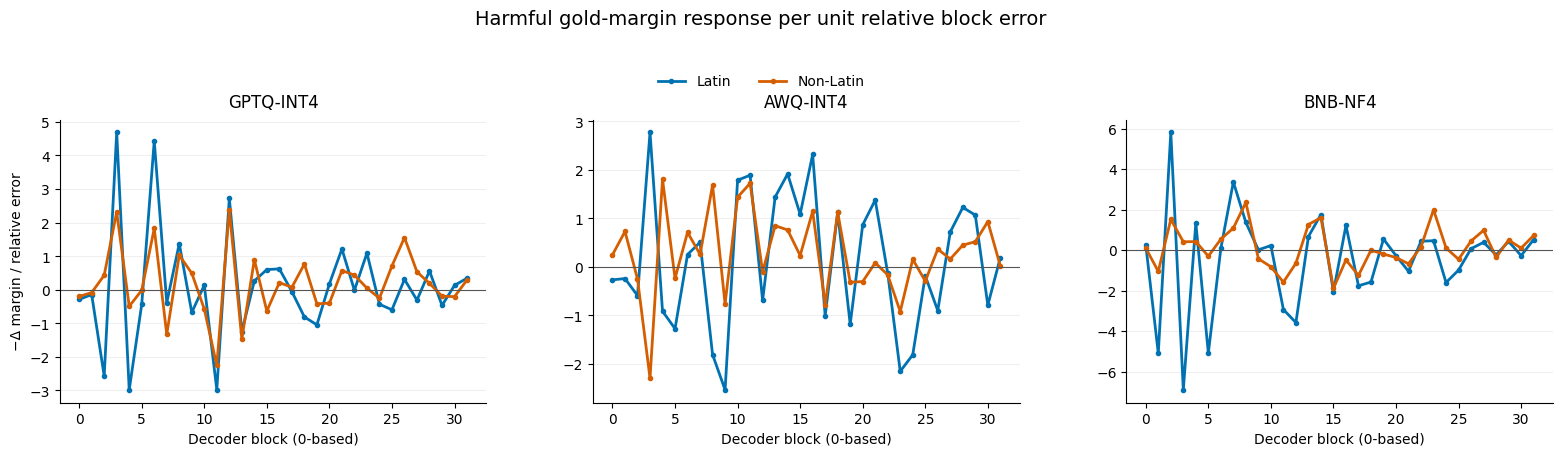

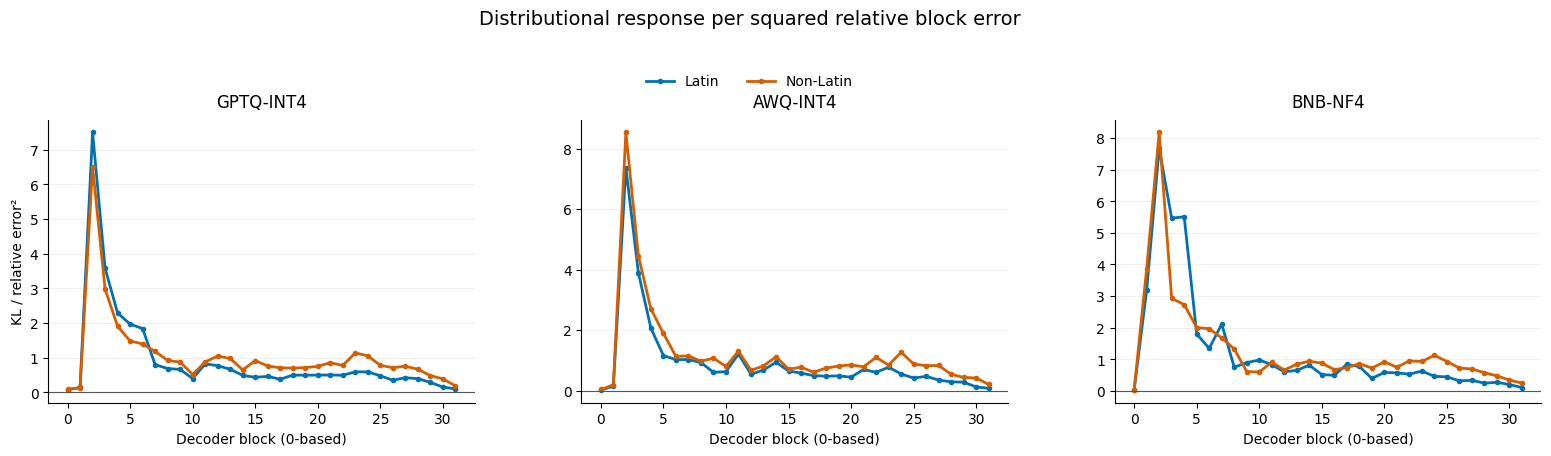

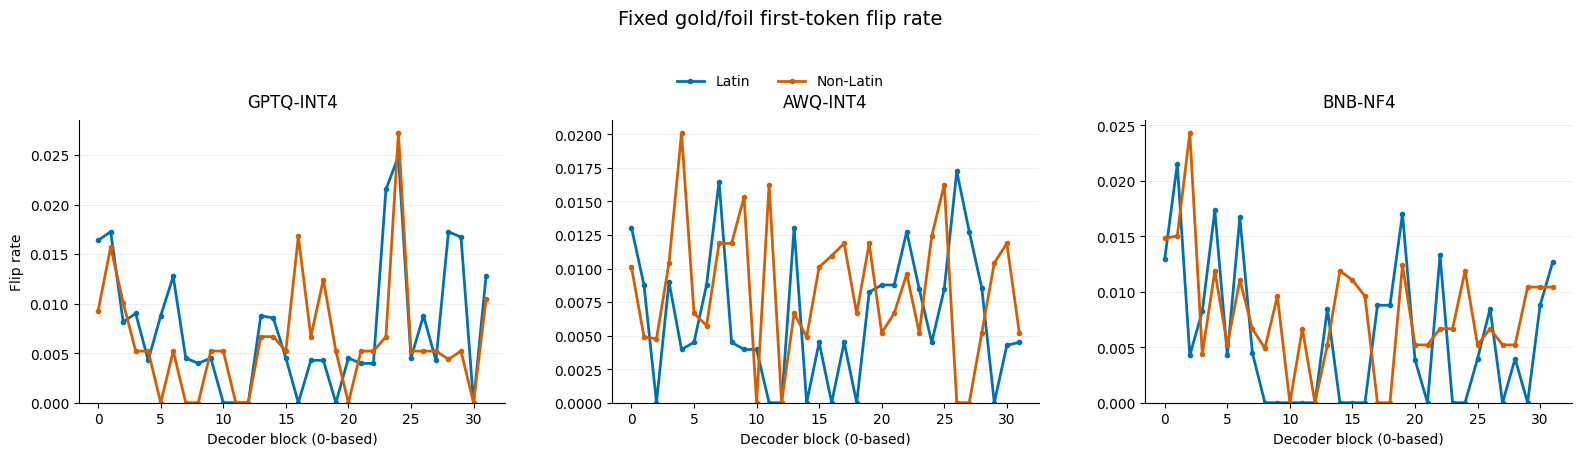

In [10]:
# One language contributes one observation to each script-group curve.
language_level = (usable.groupby(
    ['method', 'layer', 'script_group', 'language'], as_index=False
).agg(
    n_facts=('record_id', 'nunique'),
    median_margin_sensitivity=('margin_sensitivity', 'median'),
    median_kl_sensitivity=('kl_sensitivity', 'median'),
    harmful_fraction=('harmful_margin_change', 'mean'),
    first_token_flip_rate=('first_token_flip', 'mean'),
    mean_relative_error=('direct_error_all_token_ratio', 'mean'),
    mean_raw_delta_margin=('delta_margin', 'mean'),
))
group_level = (language_level.groupby(
    ['method', 'layer', 'script_group'], as_index=False
).agg(
    languages=('language', 'nunique'),
    facts_sum=('n_facts', 'sum'),
    median_margin_sensitivity=('median_margin_sensitivity', 'mean'),
    median_kl_sensitivity=('median_kl_sensitivity', 'mean'),
    harmful_fraction=('harmful_fraction', 'mean'),
    first_token_flip_rate=('first_token_flip_rate', 'mean'),
    mean_relative_error=('mean_relative_error', 'mean'),
    mean_raw_delta_margin=('mean_raw_delta_margin', 'mean'),
))
language_level.to_csv(
    SENSITIVITY_DIR / 'sensitivity_by_language_layer.csv',
    index=False, encoding='utf-8-sig')
group_level.to_csv(
    SENSITIVITY_DIR / 'sensitivity_by_script_group_layer.csv',
    index=False, encoding='utf-8-sig')

plot_specs = [
    ('median_margin_sensitivity',
     'Harmful gold-margin response per unit relative block error',
     '−Δ margin / relative error'),
    ('median_kl_sensitivity',
     'Distributional response per squared relative block error',
     'KL / relative error²'),
    ('first_token_flip_rate',
     'Fixed gold/foil first-token flip rate', 'Flip rate'),
]
methods = [m for m in METHOD_ORDER if m in set(group_level.method)]
for metric, title, ylabel in plot_specs:
    fig, axes = plt.subplots(1, len(methods), figsize=(5.5*len(methods), 4.8),
                             sharex=True, sharey=False)
    if len(methods) == 1:
        axes = [axes]
    fig.subplots_adjust(left=0.075, right=0.98, bottom=0.17,
                        top=0.76, wspace=0.25)
    for ax, method in zip(axes, methods):
        panel = group_level[group_level.method.eq(method)]
        for group in GROUP_ORDER:
            curve = panel[panel.script_group.eq(group)].sort_values('layer')
            ax.plot(curve.layer, curve[metric], linewidth=2,
                    marker='o', markersize=3, color=GROUP_COLOR[group],
                    label=group)
        ax.set_title(method, fontsize=12, pad=9)
        ax.set_xlabel('Decoder block (0-based)')
        ax.grid(axis='y', alpha=0.2)
        ax.spines[['top', 'right']].set_visible(False)
        if metric == 'first_token_flip_rate':
            ax.set_ylim(bottom=0)
        else:
            ax.axhline(0, color='#555555', linewidth=0.8)
    axes[0].set_ylabel(ylabel)
    fig.legend(*axes[0].get_legend_handles_labels(),
               loc='upper center', bbox_to_anchor=(0.5, 0.88),
               ncol=2, frameon=False)
    fig.suptitle(title, y=0.99, fontsize=14)
    fig.savefig(SENSITIVITY_DIR / f'sensitivity_{metric}.png',
                dpi=220, bbox_inches='tight')
    plt.show()


## 早层 0–7 的配对对比

下表先将各语言在 0–7 层的样本汇总，再对同组的六种语言等权平均。`Non-Latin − Latin` 为正时，分别表示更有害的 margin 响应、更大的无方向 KL 响应或更高的首 token 翻转率。bootstrap 以共同的 `record_id` 为单位重抽样，保留同一事实的跨语言配对结构。

In [11]:
def group_metric_from_rows(frame, metric):
    by_language = (frame.groupby(['script_group', 'language'])[metric]
                   .agg('mean' if metric in
                        ['first_token_flip', 'harmful_margin_change'] else 'median'))
    return {
        group: float(by_language.xs(group, level='script_group').mean())
        for group in GROUP_ORDER
    }

def paired_early_bootstrap(method_frame, metric, repeats=BOOTSTRAP_REPEATS):
    # Matrix: language × shared English-anchored fact × layer.
    languages = {g: sorted(method_frame.loc[
        method_frame.script_group.eq(g), 'language'].unique()) for g in GROUP_ORDER}
    fact_ids = np.sort(raw.record_id.unique())
    layers = EARLY_LAYERS
    arrays = {}
    for group in GROUP_ORDER:
        arr = np.full((len(languages[group]), len(fact_ids), len(layers)), np.nan)
        for lang_i, language in enumerate(languages[group]):
            one = method_frame[method_frame.language.eq(language)]
            pivot = one.pivot_table(index='record_id', columns='layer',
                                    values=metric, aggfunc='first')
            arr[lang_i] = pivot.reindex(index=fact_ids,
                                        columns=layers).to_numpy(float)
        arrays[group] = arr
    rng = np.random.default_rng(BOOTSTRAP_SEED)
    differences = np.empty(repeats)
    for b in range(repeats):
        sampled_facts = rng.integers(0, len(fact_ids), size=len(fact_ids))
        group_values = {}
        for group, arr in arrays.items():
            per_language = arr[:, sampled_facts, :].reshape(arr.shape[0], -1)
            if metric in ['first_token_flip', 'harmful_margin_change']:
                per_language = np.nanmean(per_language, axis=1)
            else:
                per_language = np.nanmedian(per_language, axis=1)
            group_values[group] = np.nanmean(per_language)
        differences[b] = group_values['Non-Latin'] - group_values['Latin']
    return tuple(np.quantile(differences, [0.025, 0.975]))

early = usable[usable.layer.isin(EARLY_LAYERS)].copy()
early_rows = []
for method in methods:
    subset = early[early.method.eq(method)]
    for metric in ['margin_sensitivity', 'kl_sensitivity',
                   'harmful_margin_change', 'first_token_flip']:
        point = group_metric_from_rows(subset, metric)
        ci_low, ci_high = paired_early_bootstrap(subset, metric)
        early_rows.append({
            'method': method, 'metric': metric,
            'latin': point['Latin'], 'nonlatin': point['Non-Latin'],
            'nonlatin_minus_latin': point['Non-Latin'] - point['Latin'],
            'bootstrap_95_low': ci_low, 'bootstrap_95_high': ci_high,
            'early_layers': '0-7',
        })
early_summary = pd.DataFrame(early_rows)
early_summary.to_csv(
    SENSITIVITY_DIR / 'sensitivity_early0_7_group_comparison.csv',
    index=False, encoding='utf-8-sig')
display(early_summary.round(4))

for _, row in early_summary.iterrows():
    interval_excludes_zero = (row.bootstrap_95_low > 0 or
                              row.bootstrap_95_high < 0)
    print(f'{row.method:9s} | {row.metric:23s} | '
          f'Non-Latin − Latin = {row.nonlatin_minus_latin:+.4f} '
          f'[95% {row.bootstrap_95_low:+.4f}, {row.bootstrap_95_high:+.4f}]'
          f' | interval excludes 0: {interval_excludes_zero}')


,method,metric,latin,nonlatin,nonlatin_minus_latin,bootstrap_95_low,bootstrap_95_high,early_layers
0,GPTQ-INT4,margin_sensitivity,0.1393,0.0069,-0.1324,-0.7061,0.3206,0-7
1,GPTQ-INT4,kl_sensitivity,1.0314,1.1253,0.0938,-0.3715,0.6395,0-7
2,GPTQ-INT4,harmful_margin_change,0.4843,0.4654,-0.0188,-0.0504,0.0136,0-7
3,GPTQ-INT4,first_token_flip,0.0101,0.0063,-0.0038,-0.0140,0.0065,0-7
4,AWQ-INT4,margin_sensitivity,-0.3313,0.2485,0.5798,0.1640,1.0152,0-7
5,AWQ-INT4,kl_sensitivity,0.8798,1.4914,0.6116,0.0550,1.3859,0-7
6,AWQ-INT4,harmful_margin_change,0.4444,0.4774,0.0331,0.0008,0.0650,0-7
7,AWQ-INT4,first_token_flip,0.0081,0.0093,0.0013,-0.0088,0.0114,0-7
8,BNB-NF4,margin_sensitivity,-0.2773,0.1515,0.4287,-0.0055,1.2801,0-7
9,BNB-NF4,kl_sensitivity,1.8001,2.0754,0.2753,-1.0395,1.4127,0-7


GPTQ-INT4 | margin_sensitivity      | Non-Latin − Latin = -0.1324 [95% -0.7061, +0.3206] | interval excludes 0: False
GPTQ-INT4 | kl_sensitivity          | Non-Latin − Latin = +0.0938 [95% -0.3715, +0.6395] | interval excludes 0: False
GPTQ-INT4 | harmful_margin_change   | Non-Latin − Latin = -0.0188 [95% -0.0504, +0.0136] | interval excludes 0: False
GPTQ-INT4 | first_token_flip        | Non-Latin − Latin = -0.0038 [95% -0.0140, +0.0065] | interval excludes 0: False
AWQ-INT4  | margin_sensitivity      | Non-Latin − Latin = +0.5798 [95% +0.1640, +1.0152] | interval excludes 0: True
AWQ-INT4  | kl_sensitivity          | Non-Latin − Latin = +0.6116 [95% +0.0550, +1.3859] | interval excludes 0: True
AWQ-INT4  | harmful_margin_change   | Non-Latin − Latin = +0.0331 [95% +0.0008, +0.0650] | interval excludes 0: True
AWQ-INT4  | first_token_flip        | Non-Latin − Latin = +0.0013 [95% -0.0088, +0.0114] | interval excludes 0: False
BNB-NF4   | margin_sensitivity      | Non-Latin − Latin = +

## 判断规则

- `margin_sensitivity` 与首 token 翻转率都更高：支持“相同局部误差对该语言组的**答案决策**更有害”。
- 只有 `kl_sensitivity` 更高：仅支持“输出**分布**更敏感”，不能据此解释准确率差异。
- 区间跨 0、不同量化方法不一致，或首 token 翻转极少：报告探索性趋势，不写成普适机制。

这是单层误差注入 FP16 下游的**有限扰动响应**，不是严格的无穷小梯度，也不是完整量化模型的总误差分解。组间样本经过 FP16 正确性筛选，且 tokenization、语言资源与事实难度仍可能混杂。